# MAL Anime: catalog, scores, and audience

A cross-sectional analysis of the acquired MyAnimeList catalog, grouped by release metadata and current MAL engagement.

**Interpretation:** MAL scores, ranks, and popularity are snapshots from extraction, not historical measurements. Genre and studio credits are many-to-many. Group comparisons use minimum sample thresholds; weighted scores use anime mean scores weighted by scoring-user counts and are estimates, not raw-vote aggregates.

**Contents**
1. [Dataset overview](#Dataset-overview)
2. [Catalog rhythm](#Catalog-rhythm) — release volume and seasonal cadence
3. [Overall score distribution](#Overall-score-distribution)
4. [Score consistency by format](#Score-consistency-by-format)
5. [Genre volume vs. quality](#Genre-volume-vs.-quality)
6. [Score by source material](#Score-by-source-material)
7. [Audience attention and score](#Audience-attention-and-score)
8. [Studio output vs. quality](#Studio-output-vs.-quality)
9. [Studio output over time](#Studio-output-over-time)
10. [Episode-length bands](#Episode-length-bands)
11. [Highest-ranked titles](#Highest-ranked-titles)

## Dataset overview

Loads the PostgreSQL connection and every query result used throughout this report, then summarizes how complete the extracted catalog is.

In [1]:
from pathlib import Path
import sys

from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

project_root = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
sys.path.insert(0, str(project_root))

from analysis import queries
from load_sql.sql_loader import get_engine

sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 120, 'axes.titleweight': 'bold'})
engine = get_engine()

overview = queries.dataset_overview(engine).iloc[0]
df_year = queries.catalog_by_year(engine)
df_season = queries.seasonal_catalog(engine)
df_formats = queries.media_type_score_profile(engine, min_count=30)
df_genres = queries.genre_score_profile(engine, min_count=100)
df_studio_year = queries.studio_output_by_year(engine)
df_studios = queries.studio_score_profile(engine, min_count=30)
df_sources = queries.source_score_profile(engine, min_count=100)
df_ratings = queries.rating_score_profile(engine, min_count=30)
df_episodes = queries.episode_band_score_profile(engine, min_count=30)
df_audience = queries.audience_score_sample(engine, limit=5000)
df_top = queries.top_ranked_anime(engine, min_scoring_users=1000, limit=25)

coverage = pd.DataFrame({
    'Metric': ['Anime records', 'Scored anime', 'Release year known', 'Episode count known', 'Audience count known'],
    'Count': [overview['anime_count'], overview['scored_count'], overview['dated_count'], overview['episode_count'], overview['audience_count']],
})
coverage['Coverage'] = coverage['Count'] / overview['anime_count']
display(coverage.style.format({'Count': '{:,.0f}', 'Coverage': '{:.1%}'}).hide(axis='index'))
print(f"Mean MAL score: {overview['mean_score']:.2f} | Median: {overview['median_score']:.2f} | Release years: {int(overview['first_release_year'])}-{int(overview['last_release_year'])}")

Metric,Count,Coverage
Anime records,"27,503",100.0%
Scored anime,"19,352",70.4%
Release year known,"22,952",83.5%
Episode count known,"27,503",100.0%
Audience count known,"27,503",100.0%


Mean MAL score: 6.39 | Median: 6.37 | Release years: 1917-2027


## Catalog rhythm

Release volume shows how the catalog and formats changed over time; the seasonal heatmap highlights the annual cadence. Years with incomplete MAL dates are excluded from these views.

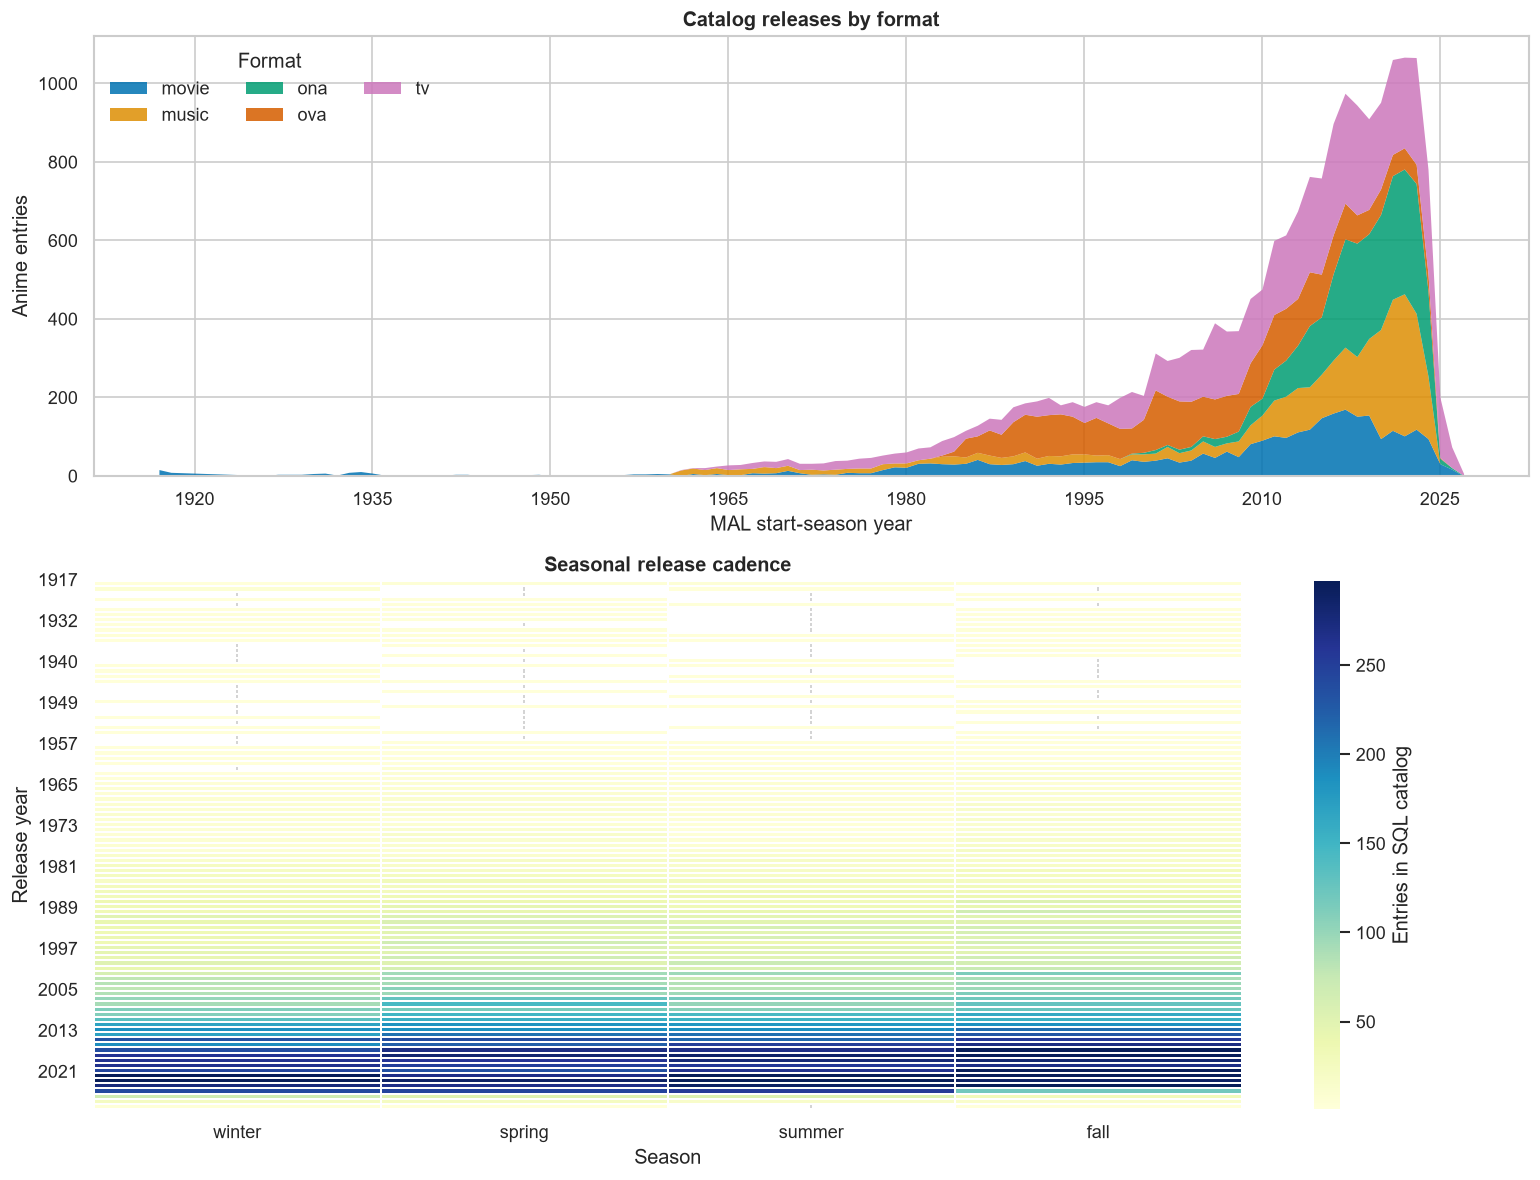

In [2]:
type_totals = df_year.groupby('media_type', dropna=True)['anime_count'].sum().sort_values(ascending=False)
top_types = type_totals.head(5).index
annual = (
    df_year[df_year['media_type'].isin(top_types)]
    .pivot(index='year', columns='media_type', values='anime_count')
    .fillna(0)
    .sort_index()
)
season_order = ['winter', 'spring', 'summer', 'fall']
season_heat = df_season.pivot(index='year', columns='season', values='anime_count').reindex(columns=season_order)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 10), gridspec_kw={'height_ratios': [1, 1.2]})
annual.plot.area(ax=ax1, alpha=0.86, linewidth=0)
ax1.set(title='Catalog releases by format', xlabel='MAL start-season year', ylabel='Anime entries')
ax1.legend(title='Format', ncol=3, frameon=False, loc='upper left')
ax1.xaxis.set_major_locator(plt.MaxNLocator(12))

sns.heatmap(season_heat, cmap='YlGnBu', robust=True, linewidths=0.15, linecolor='white', ax=ax2,
            cbar_kws={'label': 'Entries in SQL catalog'})
ax2.set(title='Seasonal release cadence', xlabel='Season', ylabel='Release year')
ax2.set_yticks(range(0, len(season_heat.index), max(1, len(season_heat.index) // 12)))
ax2.set_yticklabels(season_heat.index[::max(1, len(season_heat.index) // 12)], rotation=0)
fig.tight_layout()
plt.show()

In [3]:
peak_year = int(annual.sum(axis=1).idxmax())
peak_year_count = int(annual.sum(axis=1).max())
leading_format = type_totals.index[0]
busiest_season = df_season.groupby('season')['anime_count'].sum().idxmax()
display(Markdown(
    f"**Findings:** the busiest release year in the catalog is **{peak_year}** with "
    f"**{peak_year_count:,}** entries; **{leading_format}** is the highest-volume format overall, "
    f"and **{busiest_season}** is the most common release season."
))

**Findings:** the busiest release year in the catalog is **2022** with **1,067** entries; **tv** is the highest-volume format overall, and **fall** is the most common release season.

## Overall score distribution

Distribution of MAL mean scores across every scored anime in the catalog. Scores are MAL means, not raw voter-level data.

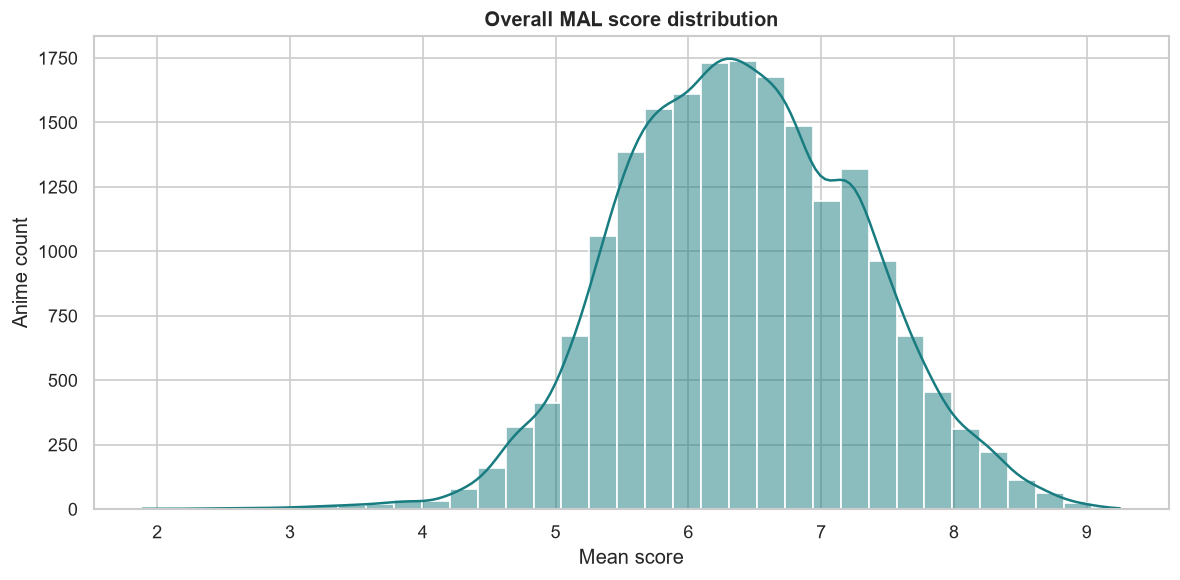

In [4]:
score_series = queries.score_distribution(engine)['mean_score']
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(score_series, bins=35, kde=True, color='#187c80', ax=ax)
ax.set(title='Overall MAL score distribution', xlabel='Mean score', ylabel='Anime count')
fig.tight_layout()
plt.show()

In [5]:
display(Markdown(
    f"**Findings:** scores cluster around a median of **{score_series.median():.2f}**, with the middle 50% of "
    f"anime falling between **{score_series.quantile(0.25):.2f}** and **{score_series.quantile(0.75):.2f}**."
))

**Findings:** scores cluster around a median of **6.37**, with the middle 50% of anime falling between **5.76** and **7.03**.

## Score consistency by format

Median score and interquartile range for each format with at least 30 scored anime, ordered from lowest to highest median. A narrower bar means scores for that format are more consistent.

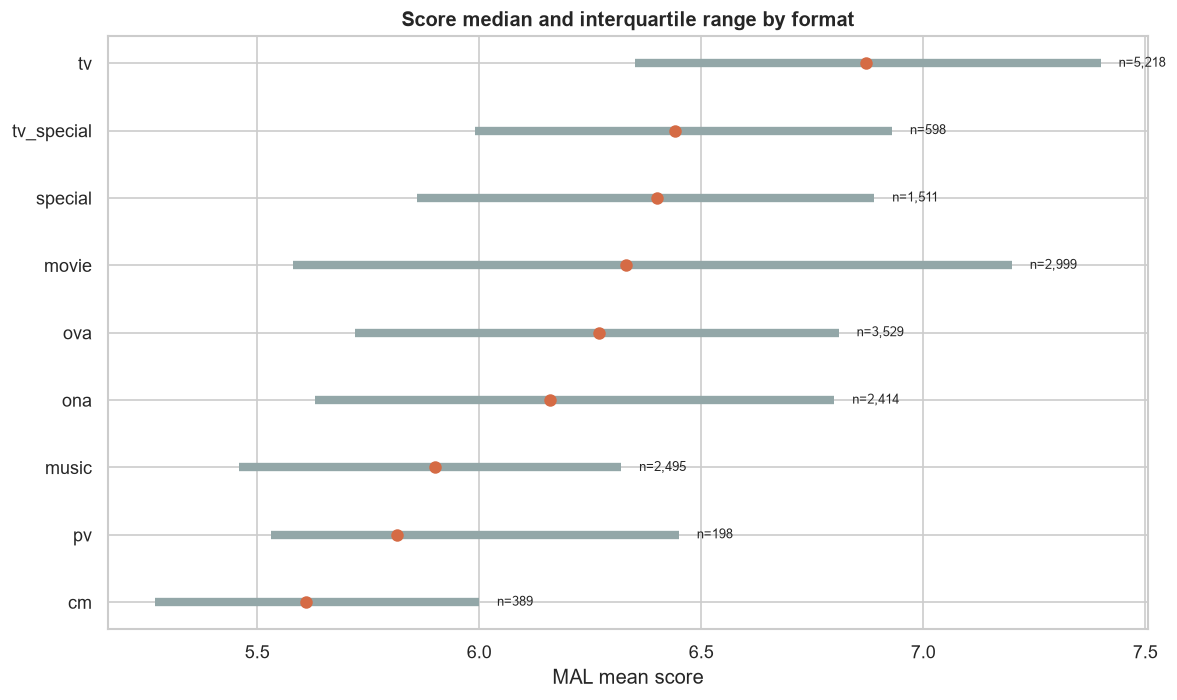

In [6]:
format_plot = df_formats.sort_values('median_score')
fig, ax = plt.subplots(figsize=(10, 6))
for position, (_, row) in enumerate(format_plot.iterrows()):
    ax.hlines(position, row['q1_score'], row['q3_score'], color='#93a7a8', linewidth=5)
    ax.scatter(row['median_score'], position, color='#d56b45', s=42, zorder=3)
    ax.text(row['q3_score'] + 0.04, position, f"n={int(row['scored_count']):,}", va='center', fontsize=8)
ax.set_yticks(range(len(format_plot)), format_plot['media_type'])
ax.set(title='Score median and interquartile range by format', xlabel='MAL mean score', ylabel='')
fig.tight_layout()
plt.show()

In [7]:
best_format = df_formats.loc[df_formats['median_score'].idxmax()]
formats_iqr = df_formats.assign(iqr=df_formats['q3_score'] - df_formats['q1_score'])
tightest_format = formats_iqr.loc[formats_iqr['iqr'].idxmin()]
display(Markdown(
    f"**Findings:** **{best_format['media_type']}** has the highest median score "
    f"({best_format['median_score']:.2f}); **{tightest_format['media_type']}** scores most consistently, "
    f"with the narrowest interquartile range ({tightest_format['q1_score']:.2f}-{tightest_format['q3_score']:.2f})."
))

**Findings:** **tv** has the highest median score (6.87); **cm** scores most consistently, with the narrowest interquartile range (5.27-6.00).

## Genre volume vs. quality

Each point is a genre with at least 100 scored anime. Point size reflects how many of that genre's anime are scored; color reflects the scoring-user-weighted score. The x-axis is logarithmic because genre volume is highly skewed.

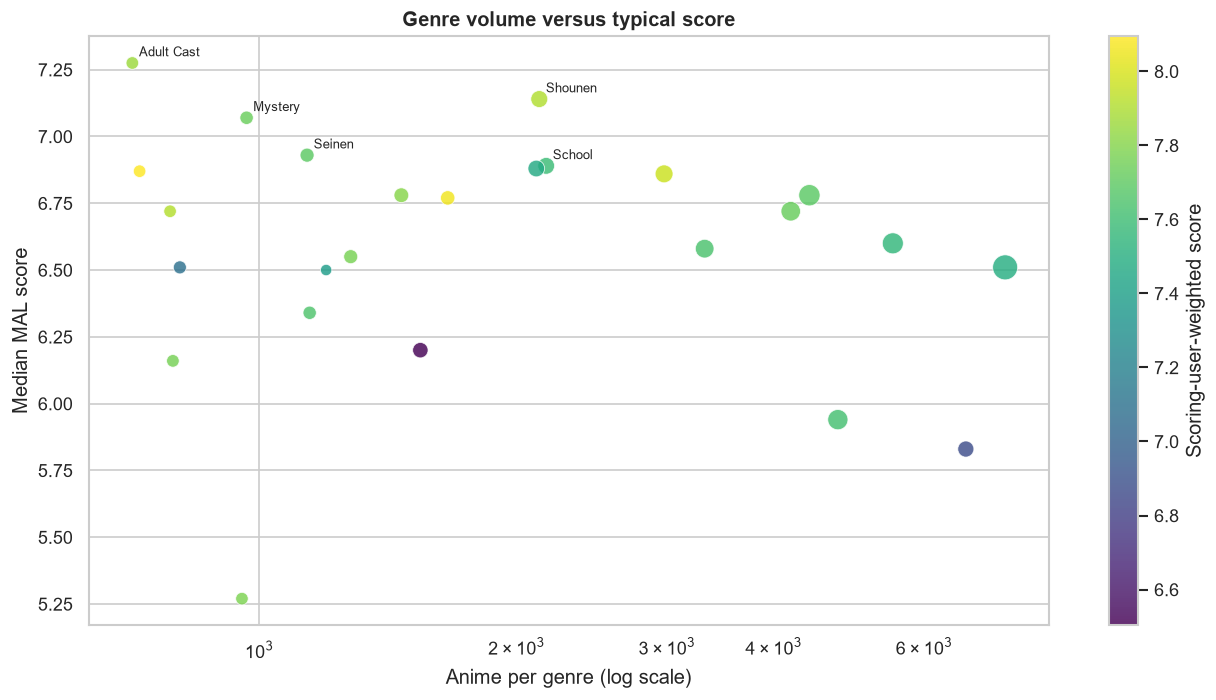

In [8]:
volume_genres = df_genres.nlargest(25, 'anime_count').copy()
point_sizes = 35 + 190 * volume_genres['scored_count'] / volume_genres['scored_count'].max()
fig, ax = plt.subplots(figsize=(11, 6))
points = ax.scatter(volume_genres['anime_count'], volume_genres['median_score'],
                     s=point_sizes, c=volume_genres['weighted_score'], cmap='viridis',
                     alpha=0.82, edgecolor='white', linewidth=0.5)
ax.set_xscale('log')
ax.set(title='Genre volume versus typical score', xlabel='Anime per genre (log scale)', ylabel='Median MAL score')
fig.colorbar(points, ax=ax, label='Scoring-user-weighted score')
for _, row in volume_genres.nlargest(5, 'median_score').iterrows():
    ax.annotate(row['genre'], (row['anime_count'], row['median_score']), xytext=(4, 4),
                textcoords='offset points', fontsize=8)
fig.tight_layout()
plt.show()

In [9]:
top_genre = volume_genres.loc[volume_genres['median_score'].idxmax()]
biggest_genre = volume_genres.loc[volume_genres['anime_count'].idxmax()]
display(Markdown(
    f"**Findings:** among the 25 highest-volume genres, **{top_genre['genre']}** has the highest median score "
    f"({top_genre['median_score']:.2f}); **{biggest_genre['genre']}** is the largest by volume "
    f"({int(biggest_genre['anime_count']):,} anime). Across all {len(df_genres)} genres meeting the sample threshold, "
    f"volume and typical score show no strong relationship."
))

**Findings:** among the 25 highest-volume genres, **Adult Cast** has the highest median score (7.28); **Comedy** is the largest by volume (7,462 anime). Across all 61 genres meeting the sample threshold, volume and typical score show no strong relationship.

## Score by source material

Median score for the ten most common source materials (manga, light novel, original, etc.), each with at least 100 scored anime.

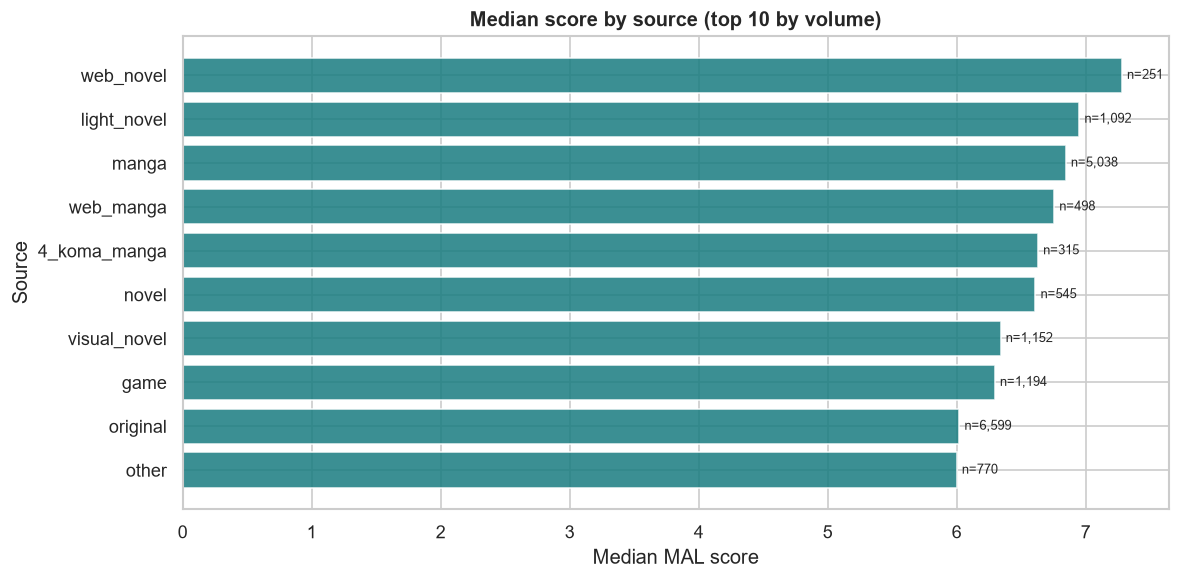

In [10]:
source_plot = df_sources.nlargest(10, 'anime_count').sort_values('median_score')
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(source_plot['source'], source_plot['median_score'], color='#187c80', alpha=0.85)
ax.set(title='Median score by source (top 10 by volume)', xlabel='Median MAL score', ylabel='Source')
for position, (_, row) in enumerate(source_plot.iterrows()):
    ax.text(row['median_score'] + 0.04, position, f"n={int(row['scored_count']):,}", va='center', fontsize=8)
fig.tight_layout()
plt.show()

In [11]:
best_source = source_plot.loc[source_plot['median_score'].idxmax()]
display(Markdown(
    f"**Findings:** among the ten most common source materials, **{best_source['source']}** has the highest "
    f"median score ({best_source['median_score']:.2f}, n={int(best_source['scored_count']):,})."
))

**Findings:** among the ten most common source materials, **web_novel** has the highest median score (7.28, n=251).

### Score by content rating

Median score by MAL content rating (e.g. PG-13, R, R+), each with at least 30 scored anime.

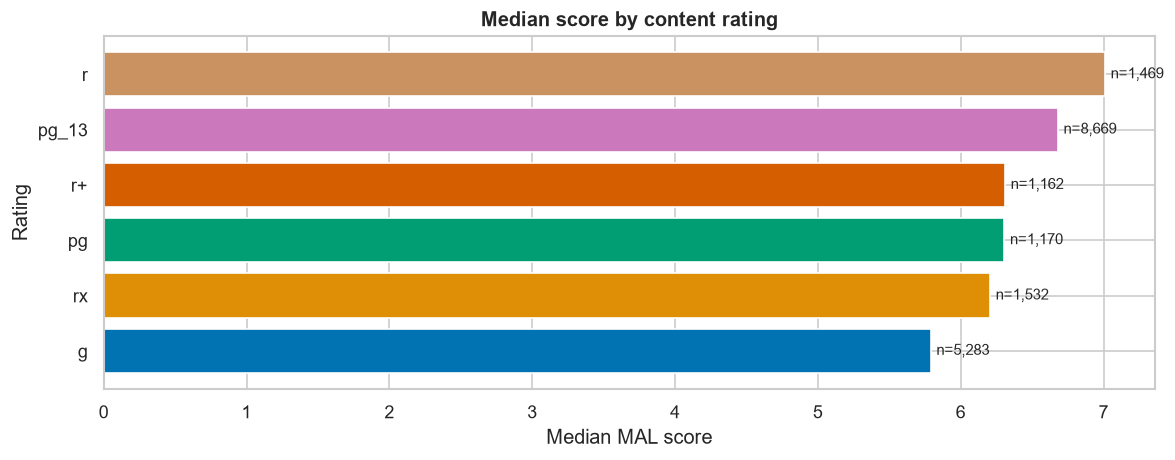

**Findings:** **r**-rated anime have the highest median score (7.01, n=1,469).

In [12]:
rating_plot = df_ratings.sort_values('median_score')
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(rating_plot['rating'], rating_plot['median_score'], color=sns.color_palette('colorblind', len(rating_plot)))
ax.set(title='Median score by content rating', xlabel='Median MAL score', ylabel='Rating')
for position, (_, row) in enumerate(rating_plot.iterrows()):
    ax.text(row['median_score'] + 0.04, position, f"n={int(row['scored_count']):,}", va='center', fontsize=9)
fig.tight_layout()
plt.show()

best_rating = rating_plot.loc[rating_plot['median_score'].idxmax()]
display(Markdown(
    f"**Findings:** **{best_rating['rating']}**-rated anime have the highest median score "
    f"({best_rating['median_score']:.2f}, n={int(best_rating['scored_count']):,})."
))

## Audience attention and score

The audience scatter uses a deterministic 5,000-title sample so dense regions stay legible. MAL list-user counts are highly skewed, so the x-axis is logarithmic; rank and popularity remain separate fields.

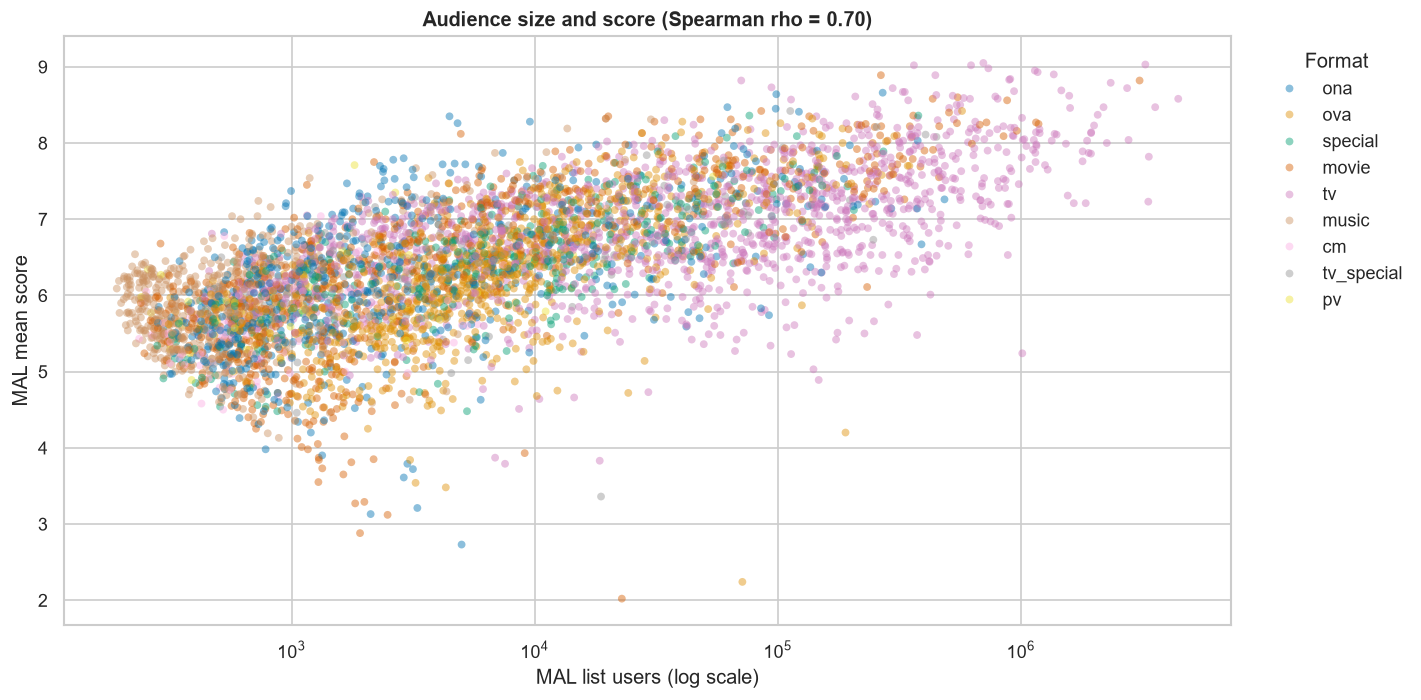

Sample size: 5,000 anime; user count is not a measure of score confidence by itself.


In [13]:
spearman = df_audience[['mean_score', 'num_list_users']].corr(method='spearman').iloc[0, 1]
fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(data=df_audience, x='num_list_users', y='mean_score', hue='media_type',
                alpha=0.45, s=22, linewidth=0, palette='colorblind', ax=ax)
ax.set_xscale('log')
ax.set(title=f'Audience size and score (Spearman rho = {spearman:.2f})',
       xlabel='MAL list users (log scale)', ylabel='MAL mean score')
ax.legend(title='Format', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
fig.tight_layout()
plt.show()
print(f"Sample size: {len(df_audience):,} anime; user count is not a measure of score confidence by itself.")

In [14]:
strength = 'weak' if abs(spearman) < 0.3 else ('moderate' if abs(spearman) < 0.6 else 'strong')
display(Markdown(
    f"**Findings:** audience size and score show a **{strength}** monotonic relationship "
    f"(Spearman rho = {spearman:.2f}) across the {len(df_audience):,}-anime sample; a large audience is not "
    f"a reliable predictor of a high MAL score."
))

**Findings:** audience size and score show a **strong** monotonic relationship (Spearman rho = 0.70) across the 5,000-anime sample; a large audience is not a reliable predictor of a high MAL score.

## Studio output vs. quality

Each point is one of the 30 highest-output studios. Studio credits can overlap, so each studio count is distinct within that studio, and the same anime may appear under multiple studios.

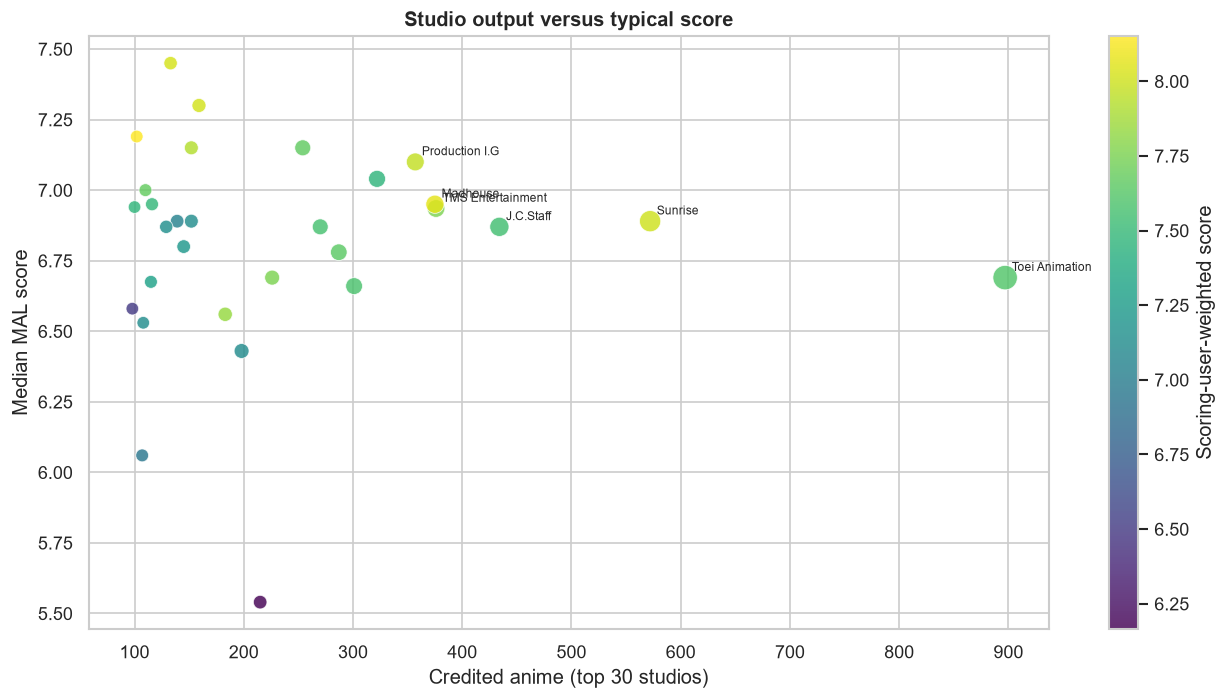

In [15]:
studio_plot = df_studios.nlargest(30, 'anime_count').copy()
studio_sizes = 35 + 180 * studio_plot['scored_count'] / studio_plot['scored_count'].max()
fig, ax = plt.subplots(figsize=(11, 6))
studio_points = ax.scatter(studio_plot['anime_count'], studio_plot['median_score'],
                           s=studio_sizes, c=studio_plot['weighted_score'], cmap='viridis',
                           alpha=0.82, edgecolor='white', linewidth=0.5)
ax.set(title='Studio output versus typical score', xlabel='Credited anime (top 30 studios)', ylabel='Median MAL score')
fig.colorbar(studio_points, ax=ax, label='Scoring-user-weighted score')
for _, row in studio_plot.nlargest(6, 'anime_count').iterrows():
    ax.annotate(row['studio'], (row['anime_count'], row['median_score']), xytext=(4, 4),
                textcoords='offset points', fontsize=7)
fig.tight_layout()
plt.show()

In [16]:
most_prolific = studio_plot.loc[studio_plot['anime_count'].idxmax()]
best_scoring_studio = studio_plot.loc[studio_plot['median_score'].idxmax()]
display(Markdown(
    f"**Findings:** **{most_prolific['studio']}** has credited the most anime among studios in this view "
    f"({int(most_prolific['anime_count']):,}); **{best_scoring_studio['studio']}** has the highest median score "
    f"({best_scoring_studio['median_score']:.2f}) among the 30 highest-output studios."
))

**Findings:** **Toei Animation** has credited the most anime among studios in this view (897); **Kyoto Animation** has the highest median score (7.45) among the 30 highest-output studios.

## Studio output over time

Annual anime output for the eight highest-volume studios, showing how their production rhythm has shifted over the catalog's history.

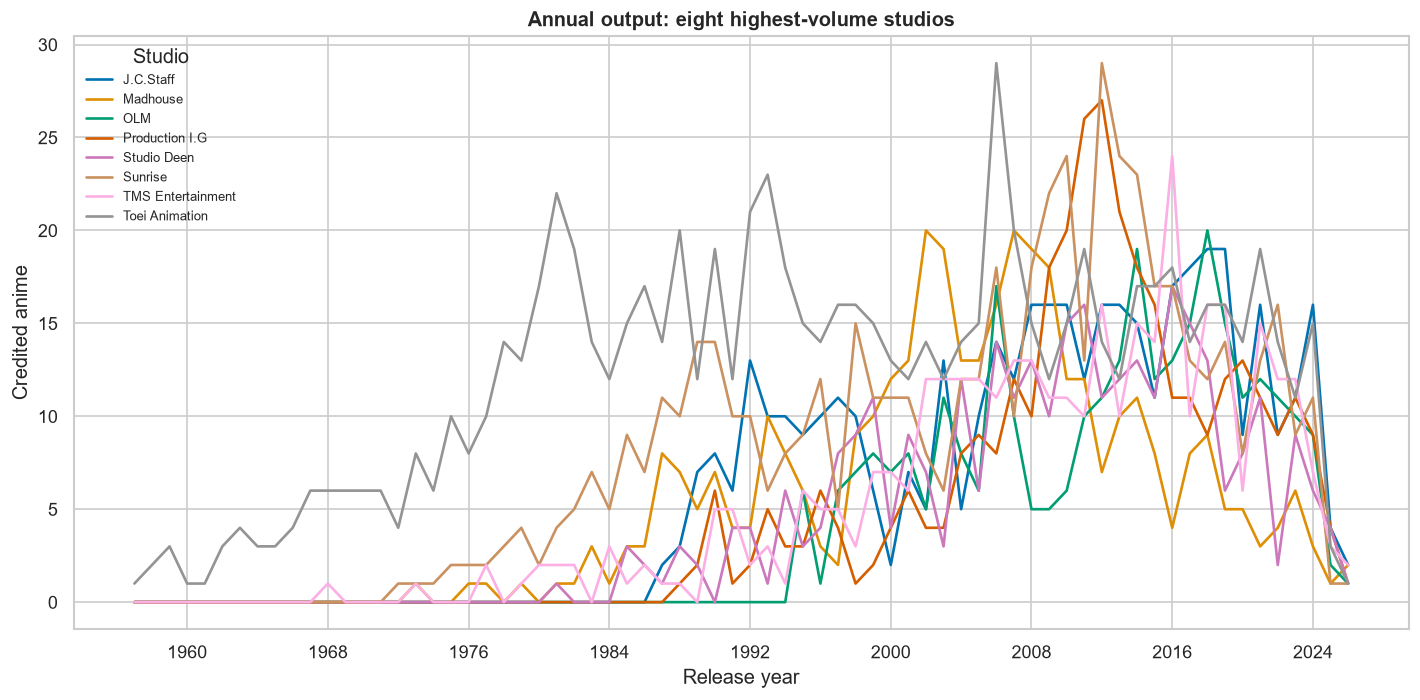

In [17]:
studio_totals = df_studio_year.groupby('studio')['anime_count'].sum().nlargest(8).index
studio_trend = (
    df_studio_year[df_studio_year['studio'].isin(studio_totals)]
    .pivot(index='year', columns='studio', values='anime_count')
    .fillna(0)
    .sort_index()
)
fig, ax = plt.subplots(figsize=(12, 6))
studio_trend.plot(ax=ax, linewidth=1.6)
ax.set(title='Annual output: eight highest-volume studios', xlabel='Release year', ylabel='Credited anime')
ax.xaxis.set_major_locator(plt.MaxNLocator(10))
ax.legend(title='Studio', fontsize=8, frameon=False, loc='upper left')
fig.tight_layout()
plt.show()

In [18]:
peak_studio_year_totals = studio_trend.sum(axis=1)
peak_studio_year = int(peak_studio_year_totals.idxmax())
leading_recent_studio = studio_trend.loc[studio_trend.index.max()].idxmax()
display(Markdown(
    f"**Findings:** among these eight studios, combined output peaked in **{peak_studio_year}**; "
    f"**{leading_recent_studio}** credited the most anime in the most recent year shown."
))

**Findings:** among these eight studios, combined output peaked in **2012**; **J.C.Staff** credited the most anime in the most recent year shown.

## Episode-length bands

Median score by episode-count band, stratified by format, with the scored sample size shown alongside each score. Formats or bands with fewer than 30 scored anime are omitted.

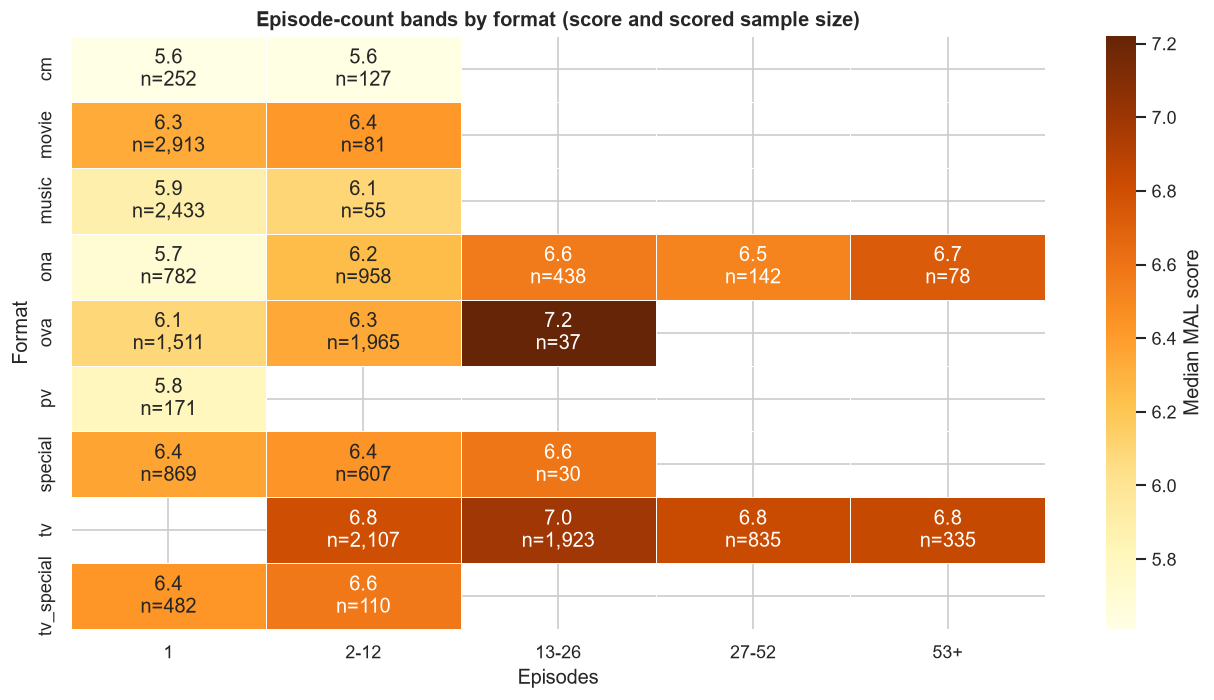

In [19]:
episode_order = ['1', '2-12', '13-26', '27-52', '53+']
episode_scores = df_episodes.pivot(index='media_type', columns='episode_band', values='median_score').reindex(columns=episode_order)
episode_labels = df_episodes.assign(
    label=df_episodes.apply(lambda row: f"{row['median_score']:.1f}\nn={int(row['scored_count']):,}", axis=1)
).pivot(index='media_type', columns='episode_band', values='label').reindex(columns=episode_order)
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(episode_scores, annot=episode_labels, fmt='', cmap='YlOrBr', linewidths=0.4,
            cbar_kws={'label': 'Median MAL score'}, ax=ax)
ax.set(title='Episode-count bands by format (score and scored sample size)', xlabel='Episodes', ylabel='Format')
fig.tight_layout()
plt.show()

In [20]:
best_combo = df_episodes.loc[df_episodes['median_score'].idxmax()]
display(Markdown(
    f"**Findings:** the highest-scoring format/length combination shown is **{best_combo['media_type']}** "
    f"at **{best_combo['episode_band']}** episodes (median {best_combo['median_score']:.2f}, "
    f"n={int(best_combo['scored_count']):,})."
))

**Findings:** the highest-scoring format/length combination shown is **ova** at **13-26** episodes (median 7.22, n=37).

## Highest-ranked titles

The table filters out entries with fewer than 1,000 scoring users and shows MAL rank, popularity, mean score, and vote count as separate measures.

In [21]:
rank_table = df_top.rename(columns={
    'title': 'Title',
    'media_type': 'Format',
    'mean_score': 'Mean score',
    'rank': 'MAL rank',
    'popularity': 'Popularity rank',
    'num_scoring_users': 'Scoring users',
})
display(
    rank_table.style
    .format({'Mean score': '{:.2f}', 'MAL rank': '{:,.0f}', 'Popularity rank': '{:,.0f}', 'Scoring users': '{:,.0f}'})
    .background_gradient(subset=['Mean score'], cmap='YlGnBu')
    .hide(axis='index')
)

Title,Format,Mean score,MAL rank,Popularity rank,Scoring users
Sousou no Frieren,tv,9.25,1,97,"939,074"
Fullmetal Alchemist: Brotherhood,tv,9.11,2,3,"2,343,888"
Steins;Gate,tv,9.07,5,14,"1,541,632"
Chainsaw Man Movie: Reze-hen,movie,9.05,6,465,"362,978"
Gintama: The Final,movie,9.05,7,"1,503","89,201"
Gintama°,tv,9.05,8,350,"275,626"
Shingeki no Kyojin Season 3 Part 2,tv,9.05,9,20,"1,826,855"
Hunter x Hunter (2011),tv,9.03,11,8,"2,014,538"
Ginga Eiyuu Densetsu,ova,9.02,12,756,"89,461"
Gintama',tv,9.02,13,407,"260,971"


In [22]:
top_title = df_top.iloc[0]
tv_share = (df_top['media_type'] == 'tv').mean()
display(Markdown(
    f"**Findings:** **{top_title['title']}** tops the filtered ranking with a mean score of "
    f"{top_title['mean_score']:.2f} from {int(top_title['num_scoring_users']):,} scoring users. "
    f"TV series make up {tv_share:.0%} of this top-{len(df_top)} list."
))

**Findings:** **Sousou no Frieren** tops the filtered ranking with a mean score of 9.25 from 939,074 scoring users. TV series make up 76% of this top-25 list.